<a href="https://colab.research.google.com/github/Jagan-kj-07/Codealpha_project1/blob/main/LanguageDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import pickle

In [ ]:
data = pd.read_csv("/archive.zip")

print(data.head())

                                                Text Language
0   Nature, in the broadest sense, is the natural...  English
1  "Nature" can refer to the phenomena of the phy...  English
2  The study of nature is a large, if not the onl...  English
3  Although humans are part of nature, human acti...  English
4  [1] The word nature is borrowed from the Old F...  English


In [ ]:
print(data.describe(include='all'))

print("\nColumns:")
print(data.columns)

print("\nDataset Shape:")
print(data.shape)

                 Text Language
count           10337    10337
unique          10267       17
top     mijn excuses.  English
freq                3     1385

Columns:
Index(['Text', 'Language'], dtype='object')

Dataset Shape:
(10337, 2)


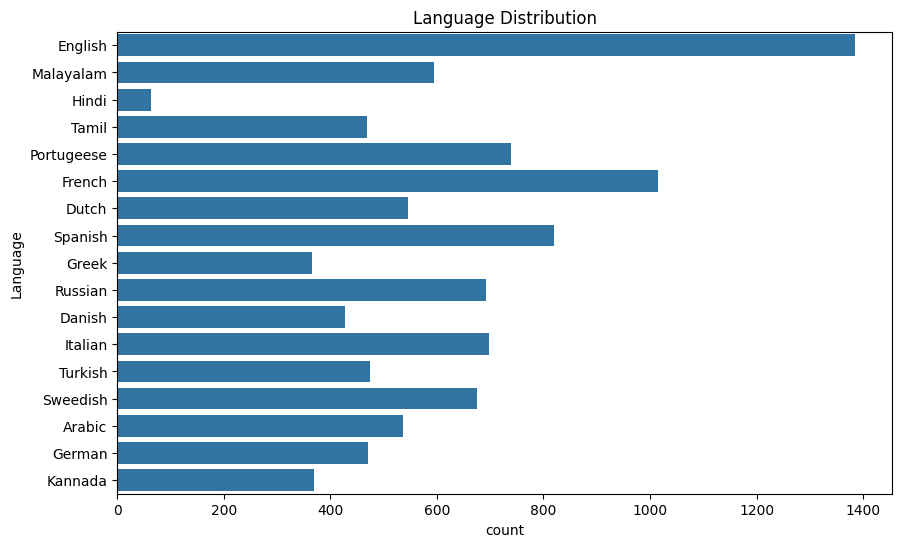

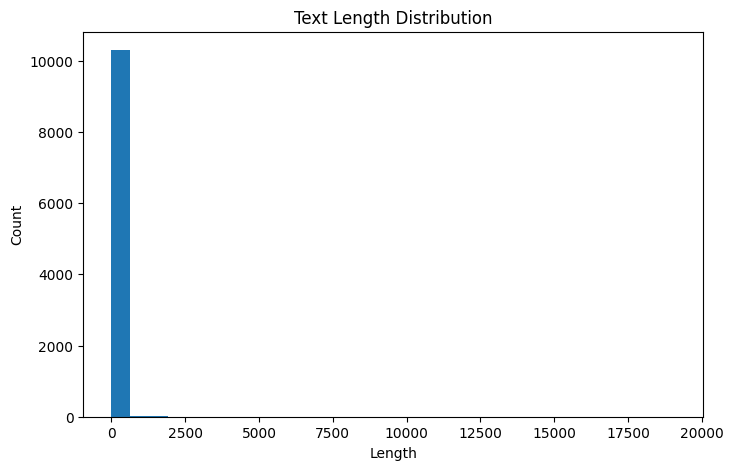

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(y=data['Language'])
plt.title("Language Distribution")
plt.show()
data['Text_Length'] = data['Text'].apply(len)

plt.figure(figsize=(8,5))
plt.hist(data['Text_Length'], bins=30)
plt.title("Text Length Distribution")
plt.xlabel("Length")
plt.ylabel("Count")
plt.show()

In [ ]:
print(data.isnull().sum())

data = data.dropna()

print("After removing null values:")
print(data.isnull().sum())

Text           0
Language       0
Text_Length    0
dtype: int64
After removing null values:
Text           0
Language       0
Text_Length    0
dtype: int64


             Text_Length
Text_Length          1.0


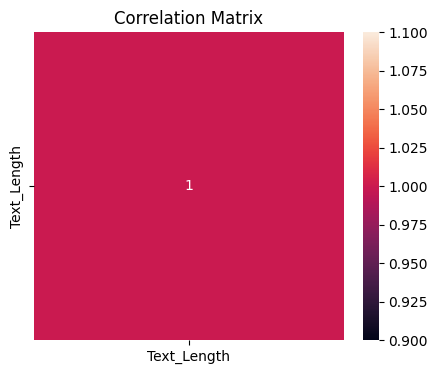

In [ ]:
numeric_data = data[['Text_Length']]

corr_matrix = numeric_data.corr()
print(corr_matrix)

plt.figure(figsize=(5,4))
sns.heatmap(corr_matrix, annot=True)
plt.title("Correlation Matrix")
plt.show()

In [ ]:
X = data['Text']
y = data['Language']
vectorizer = TfidfVectorizer()


X = vectorizer.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
svm = SVC()
svm.fit(X_train, y_train)

SVC()

In [ ]:
models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn,
    "SVM": svm
}

for name, model in models.items():

    y_pred = model.predict(X_test)

    print("\n", "="*50)
    print(name)

    print("Accuracy:",
          accuracy_score(y_test, y_pred))

    print("Precision:",
          precision_score(y_test, y_pred,
                          average='weighted'))

    print("Recall:",
          recall_score(y_test, y_pred,
                       average='weighted'))

    print("F1 Score:",
          f1_score(y_test, y_pred,
                   average='weighted'))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


Logistic Regression
Accuracy: 0.9598646034816247
Precision: 0.967130915966606
Recall: 0.9598646034816247
F1 Score: 0.9613594047827853

Confusion Matrix:
[[100   0   0   0   0   0   0   0   0   0   0   0   6   0   0   0   0]
 [  0  64   0   0   2   0   0   0   0   0   0   0   4   0   3   0   0]
 [  0   0 104   1   0   0   0   0   0   0   0   0   2   4   0   0   0]
 [  0   0   0 289   0   0   0   0   0   0   0   0   2   0   0   0   0]
 [  0   0   0   1 214   0   0   0   0   0   0   0   3   1   0   0   0]
 [  0   0   0   2   0  87   0   0   0   0   0   0   4   0   0   0   0]
 [  0   0   0   1   0   0  63   0   0   0   0   0   4   0   0   0   0]
 [  0   0   0   0   0   0   0   7   0   0   0   0   3   0   0   0   0]
 [  0   0   0   0   2   0   0   0 137   0   0   0   5   1   0   0   0]
 [  0   0   0   0   0   0   0   0   0  65   0   0   1   0   0   0   0]
 [  0   0   0   1   0   0   0   0   0   0 117   0   3   0   0   0   0]
 [  0   0   0   1   0   0   0   0   0   0   0 138   3   2   0   0

In [ ]:
pickle.dump(lr, open("logistic_regression.pkl", "wb"))
pickle.dump(dt, open("decision_tree.pkl", "wb"))
pickle.dump(rf, open("random_forest.pkl", "wb"))
pickle.dump(knn, open("knn.pkl", "wb"))
pickle.dump(svm, open("svm.pkl", "wb"))

pickle.dump(vectorizer, open("vectorizer.pkl", "wb"))
loaded_model = pickle.load(open("logistic_regression.pkl", "rb"))

In [ ]:
sample = ["यहाँ एक सरल और उपयोगी हिंदी वाक्य है:"]

sample_vector = vectorizer.transform(sample)

prediction = lr.predict(sample_vector)

print("Predicted Language:", prediction[0])

Predicted Language: Hindi


# Project Summary

This project focused on building a Language Detection system using Machine Learning. The dataset was loaded and explored to understand its structure and language distribution. Missing values were checked and removed where necessary. Text data was converted into numerical features using TF-IDF Vectorization.

Five classification algorithms were trained and evaluated: Logistic Regression, Decision Tree Classifier, Random Forest Classifier, K-Nearest Neighbors Classifier, and Support Vector Machine. The models were evaluated using Accuracy, Precision, Recall, F1 Score, and Confusion Matrix.

Among the trained models, the model with the highest accuracy was selected as the best-performing model for language prediction. All trained models were saved as pickle files for future use.

This project demonstrates how Machine Learning can be used to automatically identify the language of a given text with high accuracy.
